# KNN with PCA: financial hit or bust
Predict `success` from the existing feature-engineering CSV. KNN uses similar earlier movies: average their ratings for regression, or use their hit votes for classification. PCA compresses the encoded features before measuring similarity.

Pipeline: **impute → encode → standardize all inputs → PCA → KNN**. All learned steps are fitted again inside each chronological training fold. Current outcomes, IDs, and revenue are excluded. The existing CSVs are read-only.

Use the same **2017-11-18** outer cutoff as the other models. These are exploratory results on an already-inspected test period. Histories are retrospective and update through time.

References: [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [KNN](https://scikit-learn.org/stable/modules/neighbors).

## Tuning controls — edit here first
Change the next cell, save, then **Run All**.

| Control | What to change |
|---|---|
| `MODEL_SETTINGS` | Original neighbor count, weights, and distance (`p=2` is Euclidean). |
| `PCA_SETTINGS` | Original fraction of input variance retained, solver, and whitening. |
| `PARAM_GRID` | Trial `pca__n_components`, neighbor counts, and weights. Grid values override original settings. |
| `FEATURE_GROUPS_TO_COMPARE` | Inputs to compare; keep `All features` as the reference. |
| `CUTOFF_DATE`, `N_VALIDATION_SPLITS` | Keep consistent with the other models. |

PCA variance retained describes the **inputs**, not predictive R². Standardizing binary/category indicators gives rare categories more influence; validate this choice. PCA can discard useful signal and need not improve KNN. Distance-weighted KNN can fit training observations almost perfectly because each point is its own neighbor; validation/test results determine usefulness.

`MIN_VALIDATION_PRECISION` and `THRESHOLDS` control hit selection: require 70% mean validation precision, then maximize hit F1. If infeasible, retain the original reference and label it clearly.

In [1]:
# EDIT THIS CELL, then save and Run All. Do not change settings in later cells.
DATA_FILE = "../../data/model_data_success.csv"
CUTOFF_DATE = "2017-11-18"  # Change consistently across models for a fair comparison.
N_VALIDATION_SPLITS = 3     # Expanding chronological folds inside training.

# Fixed original-model settings. Grid values below override these during a search.
MODEL_SETTINGS = {"n_neighbors": 35, "weights": "uniform", "p": 2, "n_jobs": 2}
PCA_SETTINGS = {"n_components": 0.95, "svd_solver": "full", "whiten": False}

# CHANGE THESE LISTS to try model settings. More values mean a longer run.
# Tune PCA variance retained, neighbor count, and neighbor weighting together.
PARAM_GRID = {
    "pca__n_components": [0.80, 0.95],
    "classifier__n_neighbors": [15, 35, 75],
    "classifier__weights": ["uniform", "distance"],
}
TUNING_METRIC = "Hit_F1"
# Hit_F1 balances hit precision and recall. The precision guard below is separate.

# Remove a group to skip it; keep All features for the reference comparison.
FEATURE_GROUPS_TO_COMPARE = [
    "Movie characteristics", "+ Director history", "+ Actor history", "All features",
]
assert "All features" in FEATURE_GROUPS_TO_COMPARE

# Goal and threshold search. This is VALIDATION precision, not a test guarantee.
MIN_VALIDATION_PRECISION = 0.70
THRESHOLDS = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60,
              0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
BASE_THRESHOLD = 0.5  # Original-reference predictions; estimator search uses predict() at 0.5.
assert 0 <= MIN_VALIDATION_PRECISION <= 1
assert THRESHOLDS and all(0 < value < 1 for value in THRESHOLDS)

assert isinstance(N_VALIDATION_SPLITS, int) and N_VALIDATION_SPLITS >= 2

assert set(FEATURE_GROUPS_TO_COMPARE) <= {"Movie characteristics", "+ Director history", "+ Actor history", "All features"}


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA

movies = pd.read_csv(DATA_FILE, parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
assert movies["tmdb_id"].is_unique and movies["release_date"].notna().all()
assert movies["success"].isin([0, 1]).all()
print(f"Loaded {len(movies):,} movies | Target: success")

Loaded 6,919 movies | Target: success


## 1. Select predictors
Use movie characteristics and earlier history. Exclude both `success` and `vote_average`, identifiers, and current-movie financial outcomes. Certification and month are categorical; binary flags remain 0/1.

In [3]:
ID_COLUMNS = ["tmdb_id", "imdb_id", "title_tmdb", "release_date"]
TARGET_COLUMNS = ["success", "vote_average"]
NUMERIC_FEATURES = [
    "runtime", "log_budget", "release_year", "n_genres", "imdb_director_count",
    "dir_prior_success_rate_smoothed", "dir_prior_rating_smoothed",
    "dir_prior_rated_films_log1p", "dir_prior_films_log1p",
    "dir_years_active_log1p", "dir_prior_known_films_log1p",
    "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    "franchise_prior_films_log1p",
]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = [
    "is_sequel", "is_english", "dir_first_film", "dir_no_track_record", "backfill_unavailable", "dir_no_rating_history",
] + [column for column in movies if column.startswith("genre_")]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))
assert set(movies) == set(ID_COLUMNS + TARGET_COLUMNS + FEATURE_COLUMNS)
assert not set(ID_COLUMNS + TARGET_COLUMNS) & set(FEATURE_COLUMNS)
assert not {"budget", "revenue", "revenue_to_budget", "popularity", "vote_count"} & set(FEATURE_COLUMNS)
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()

X = movies[FEATURE_COLUMNS].copy()
# String conversion is a fixed type conversion, not a learned transformation.
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies["success"].astype(int).copy()
print(f"Predictors: {len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical, {len(BINARY_FEATURES)} binary")

Predictors: 14 numeric, 2 categorical, 24 binary


## 2. Split earlier movies from later movies
Train on approximately the earliest 80%, with later movies for testing. Keep equal release dates together. Inspect class balance before interpreting accuracy.

In [4]:
cutoff = pd.Timestamp(CUTOFF_DATE)
train_mask = movies["release_date"].lt(cutoff)
test_mask = ~train_mask
X_train, X_test = X.loc[train_mask].copy(), X.loc[test_mask].copy()
y_train, y_test = y.loc[train_mask].copy(), y.loc[test_mask].copy()
assert len(X_train) > 0 and len(X_test) > 0
assert movies.loc[train_mask, "release_date"].max() < movies.loc[test_mask, "release_date"].min()
assert set(movies.loc[train_mask, "tmdb_id"]).isdisjoint(movies.loc[test_mask, "tmdb_id"])
display(pd.DataFrame([
    ["Training", int(train_mask.sum()), movies.loc[train_mask, "release_date"].min(), movies.loc[train_mask, "release_date"].max()],
    ["Test", int(test_mask.sum()), movies.loc[test_mask, "release_date"].min(), movies.loc[test_mask, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))
assert y_train.nunique() == 2 and y_test.nunique() == 2
class_balance = pd.DataFrame({
    "Training": y_train.value_counts().reindex([0, 1], fill_value=0),
    "Test": y_test.value_counts().reindex([0, 1], fill_value=0),
})
class_balance.index = pd.Index(["Bust (0)", "Hit (1)"], name="Outcome")
display(class_balance)

,Split,Movies,First release,Last release
0,Training,5535,1990-01-12,2017-11-17
1,Test,1384,2017-11-18,2025-12-25


,Training,Test
Outcome,,
Bust (0),3506,909
Hit (1),2029,475


## 3. Fit the original KNN + PCA pipeline
Impute numeric medians and categorical modes, encode all category levels, then standardize **numeric, binary, and encoded categorical inputs together**. PCA uses the training distribution only. Each fit creates fresh transformations. KNN then measures Euclidean distance in the retained component space.

In [5]:
def make_classifier(columns):
    """Fresh preprocessing and classification for each feature set and split."""
    numeric = [column for column in NUMERIC_FEATURES if column in columns]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in BINARY_FEATURES if column in columns]
    assert set(numeric + categorical + binary) == set(columns)
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop=None, handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
        ("binary", "passthrough", binary),
    ])
    return Pipeline([
        ("preprocessor", preprocessing),
        ("scaler", StandardScaler()),
        ("pca", PCA(**PCA_SETTINGS)),
        ("classifier", KNeighborsClassifier(**MODEL_SETTINGS)),
    ])

initial_model = make_classifier(FEATURE_COLUMNS)
initial_model.fit(X_train, y_train)
initial_train_probability = initial_model.predict_proba(X_train)[:, list(initial_model.classes_).index(1)]
initial_test_probability = initial_model.predict_proba(X_test)[:, list(initial_model.classes_).index(1)]
initial_train_prediction = (initial_train_probability >= BASE_THRESHOLD).astype(int)
initial_test_prediction = (initial_test_probability >= BASE_THRESHOLD).astype(int)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_prediction = baseline.predict(np.zeros((len(y_test), 1)))
baseline_probability = baseline.predict_proba(np.zeros((len(y_test), 1)))[:, list(baseline.classes_).index(1)]
print("Majority-class baseline prediction:", int(y_train.mode().iloc[0]))

Majority-class baseline prediction: 0


## 4. Validate and tune KNN and PCA
Jointly try the top-cell variance fractions, neighbor counts, and weights using expanding chronological folds inside the training period. Every candidate refits imputation, encoding, scaling, and PCA. No later-test rows enter this search. The table reports validation means and variability.

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

# Three expanding validation windows entirely within the outer training period.
tuning_dates = movies.loc[train_mask, "release_date"]
assert tuning_dates.index.equals(X_train.index)
unique_tuning_dates = np.sort(tuning_dates.unique())
tuning_splits = []
tuning_periods = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_tuning_dates), 1):
    fit_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[earlier]).to_numpy())
    validation_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[later]).to_numpy())
    assert tuning_dates.iloc[fit_positions].max() < tuning_dates.iloc[validation_positions].min()
    assert set(fit_positions).isdisjoint(validation_positions)
    tuning_splits.append((fit_positions, validation_positions))
    tuning_periods.append({
        "Fold": fold, "Training movies": len(fit_positions), "Validation movies": len(validation_positions),
        "Training ends": tuning_dates.iloc[fit_positions].max().date(),
        "Validation starts": tuning_dates.iloc[validation_positions].min().date(),
        "Validation ends": tuning_dates.iloc[validation_positions].max().date(),
    })
display(pd.DataFrame(tuning_periods))

SCORING = {
    "Hit_F1": make_scorer(f1_score, pos_label=1, zero_division=0),
    "Hit_precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "Hit_recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "Balanced_accuracy": "balanced_accuracy", "Accuracy": "accuracy",
    "Macro_F1": "f1_macro", "ROC_AUC": "roc_auc",
}
for fit_positions, validation_positions in tuning_splits:
    assert y_train.iloc[fit_positions].nunique() == 2
    assert y_train.iloc[validation_positions].nunique() == 2

search = GridSearchCV(
    estimator=make_classifier(FEATURE_COLUMNS), param_grid=PARAM_GRID,
    scoring=SCORING, refit=TUNING_METRIC, cv=tuning_splits,
    n_jobs=1, return_train_score=True, error_score="raise",
)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
tuning_results = pd.DataFrame({
    "Settings": cv_results["params"].map(lambda params: {key.split("__", 1)[1]: value for key, value in params.items()}),
})
for metric in SCORING:
    tuning_results["Training " + metric] = cv_results["mean_train_" + metric]
    tuning_results["Validation " + metric] = cv_results["mean_test_" + metric]
tuning_results["Validation score std"] = cv_results["std_test_" + TUNING_METRIC]
tuning_results = tuning_results.sort_values("Validation " + TUNING_METRIC, ascending=False, kind="stable")
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    display(tuning_results.reset_index(drop=True).round(4))
print("Selection metric:", TUNING_METRIC)
print("Selected settings:", search.best_params_)
# GridSearchCV already refits the chosen pipeline on the full outer training period.
model = search.best_estimator_
assert set(FEATURE_COLUMNS).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
# Keep 0.5 fixed: this search tunes estimator settings, not the threshold.
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= BASE_THRESHOLD).astype(int)
test_prediction = (test_probability >= BASE_THRESHOLD).astype(int)
assert np.isfinite(test_probability).all()
assert ((test_probability >= 0) & (test_probability <= 1)).all()

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,1329,1427,1999-12-03,1999-12-10,2006-11-01
1,2,2756,1384,2006-11-01,2006-11-02,2012-03-12
2,3,4140,1395,2012-03-12,2012-03-14,2017-11-17


,Settings,Training Hit_F1,Validation Hit_F1,Training Hit_precision,Validation Hit_precision,Training Hit_recall,Validation Hit_recall,Training Balanced_accuracy,Validation Balanced_accuracy,Training Accuracy,Validation Accuracy,Training Macro_F1,Validation Macro_F1,Training ROC_AUC,Validation ROC_AUC,Validation score std
0,"{'n_neighbors': 15, 'weights': 'distance', 'n_components': 0.95}",1.0000,0.3586,1.0000,0.5718,1.0000,0.2619,1.0000,0.5729,1.0000,0.6508,1.0000,0.5587,1.0000,0.6236,0.0612
1,"{'n_neighbors': 15, 'weights': 'uniform', 'n_components': 0.95}",0.3988,0.3559,0.6617,0.5694,0.2864,0.2595,0.6052,0.5717,0.7066,0.6499,0.6022,0.5571,0.7150,0.6229,0.0612
2,"{'n_neighbors': 15, 'weights': 'distance', 'n_components': 0.8}",1.0000,0.3478,1.0000,0.5668,1.0000,0.2518,1.0000,0.5691,1.0000,0.6489,1.0000,0.5531,1.0000,0.6139,0.0650
3,"{'n_neighbors': 15, 'weights': 'uniform', 'n_components': 0.8}",0.3908,0.3400,0.6481,0.5660,0.2809,0.2440,0.6008,0.5676,0.7025,0.6489,0.5969,0.5497,0.7053,0.6114,0.0755
4,"{'n_neighbors': 35, 'weights': 'distance', 'n_components': 0.8}",1.0000,0.2667,1.0000,0.6137,1.0000,0.1739,1.0000,0.5581,1.0000,0.6549,1.0000,0.5195,1.0000,0.6322,0.1106
5,"{'n_neighbors': 35, 'weights': 'distance', 'n_components': 0.95}",1.0000,0.2653,1.0000,0.6133,1.0000,0.1731,1.0000,0.5559,1.0000,0.6524,1.0000,0.5178,1.0000,0.6356,0.0976
6,"{'n_neighbors': 35, 'weights': 'uniform', 'n_components': 0.95}",0.2390,0.2488,0.6431,0.6045,0.1504,0.1608,0.5533,0.5513,0.6815,0.6498,0.5186,0.5092,0.6770,0.6326,0.1019
7,"{'n_neighbors': 35, 'weights': 'uniform', 'n_components': 0.8}",0.2177,0.2458,0.6321,0.5992,0.1355,0.1584,0.5477,0.5523,0.6789,0.6516,0.5076,0.5086,0.6736,0.6299,0.1150
8,"{'n_neighbors': 75, 'weights': 'distance', 'n_components': 0.8}",1.0000,0.1852,1.0000,0.7556,1.0000,0.1126,1.0000,0.5440,1.0000,0.6524,1.0000,0.4811,1.0000,0.6362,0.1197
9,"{'n_neighbors': 75, 'weights': 'distance', 'n_components': 0.95}",1.0000,0.1750,1.0000,0.7142,1.0000,0.1058,1.0000,0.5417,1.0000,0.6513,1.0000,0.4759,1.0000,0.6399,0.1214


Selection metric: Hit_F1
Selected settings: {'classifier__n_neighbors': 15, 'classifier__weights': 'distance', 'pca__n_components': 0.95}


## 4b. Require 0.70 precision and judge hit F1
Use **`MIN_VALIDATION_PRECISION = 0.70`** as the mean hit precision requirement across the three chronological training-period folds. Compare feature groups, original/selected settings, and probability thresholds 0.30–0.90. Among candidates meeting the requirement, maximize mean hit F1; break ties with higher precision and proximity to threshold 0.5.

This is a validation precision requirement, not a guarantee of test precision. If no candidate qualifies, report the maximum observed validation precision and retain the original model only as a clearly labeled reference. Do not silently lower the target or use test outcomes to choose a threshold. F1 balances precision and recall equally; the separate guard supplies the precision emphasis. Reused folds give exploratory selection scores, not independent validation estimates.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings; do not redefine them here.**

In [7]:
# Preserve the previous settings-only model for an honest before/after comparison.
settings_model = model
settings_train_probability = train_probability.copy()
settings_test_probability = test_probability.copy()
settings_train_prediction = train_prediction.copy()
settings_test_prediction = test_prediction.copy()

movie_features = (
    ["runtime", "log_budget", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

improvement_configurations = {"Initial settings": {}}
initial_parameters = initial_model.get_params()
if any(initial_parameters[key] != value for key, value in search.best_params_.items()):
    improvement_configurations["Settings selected in 4"] = search.best_params_.copy()

# Store only out-of-fold scores. No test rows enter fitting or selection.
selection_rows = []
for setting_name, parameters in improvement_configurations.items():
    for feature_name, columns in feature_versions.items():
        for fold, (fit_positions, validation_positions) in enumerate(tuning_splits, 1):
            candidate = make_classifier(columns).set_params(**parameters)
            candidate.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
            actual = y_train.iloc[validation_positions]
            assert actual.nunique() == 2
            probability = candidate.predict_proba(X_train.iloc[validation_positions])[:, list(candidate.classes_).index(1)]
            for threshold in sorted(set(THRESHOLDS + [BASE_THRESHOLD])):
                predicted = (probability >= threshold).astype(int)
                selection_rows.append({
                    "Feature set": feature_name, "Settings": setting_name, "Threshold": threshold, "Fold": fold,
                    "Balanced_accuracy": balanced_accuracy_score(actual, predicted),
                    "Accuracy": accuracy_score(actual, predicted),
                    "Macro_F1": f1_score(actual, predicted, average="macro", zero_division=0),
                    "Hit_F1": f1_score(actual, predicted, pos_label=1, zero_division=0),
                    "Hit_precision": precision_score(actual, predicted, pos_label=1, zero_division=0),
                    "ROC_AUC": roc_auc_score(actual, probability),
                    "Hit_recall": recall_score(actual, predicted, zero_division=0),
                })
selection_metrics = ["Hit_F1", "Hit_precision", "Hit_recall", "Balanced_accuracy", "Accuracy", "Macro_F1", "ROC_AUC"]
selection_keys = ["Feature set", "Settings", "Threshold"]
selection_fold_results = pd.DataFrame(selection_rows)
assert selection_fold_results.groupby(selection_keys)["Fold"].nunique().eq(N_VALIDATION_SPLITS).all()
assert np.isfinite(selection_fold_results[selection_metrics].to_numpy()).all()
improvement_summary = selection_fold_results.groupby(selection_keys, sort=False).agg(
    **{metric: (metric, "mean") for metric in selection_metrics},
    Score_std=(TUNING_METRIC, "std"),
).reset_index()
# Precision guard: compare with the original all-feature model, not the majority baseline.
original_validation = improvement_summary.loc[
    improvement_summary["Feature set"].eq("All features")
    & improvement_summary["Settings"].eq("Initial settings")
    & improvement_summary["Threshold"].eq(BASE_THRESHOLD)
]
assert len(original_validation) == 1
precision_floor = (
    float(original_validation.iloc[0]["Hit_precision"])
    if MIN_VALIDATION_PRECISION is None else float(MIN_VALIDATION_PRECISION)
)
assert 0 <= precision_floor <= 1
improvement_summary["Meets precision floor"] = improvement_summary["Hit_precision"].ge(precision_floor - 1e-12)
improvement_summary["Threshold distance"] = (improvement_summary["Threshold"] - 0.5).abs()
eligible_candidates = improvement_summary.loc[improvement_summary["Meets precision floor"] & improvement_summary["Threshold"].isin(THRESHOLDS)].sort_values(
    [TUNING_METRIC, "Hit_precision", "Threshold distance"],
    ascending=[False, False, True], kind="stable",
).reset_index(drop=True)
precision_requirement_met = not eligible_candidates.empty
max_validation_precision = float(improvement_summary["Hit_precision"].max())
print(f"Required mean validation hit precision: {precision_floor:.3f}")
print(f"Maximum observed mean validation precision: {max_validation_precision:.3f}")
print(f"Eligible candidates: {len(eligible_candidates)} of {len(improvement_summary)}")
if precision_requirement_met:
    with pd.option_context("display.max_columns", None):
        display(eligible_candidates.drop(columns=["Threshold distance"]).head(12).round(4))
    winner = eligible_candidates.iloc[0]
    assert winner["Hit_precision"] >= precision_floor - 1e-12
    selection_status = "Precision/F1-selected"
    print(f"Chosen mean validation precision: {winner['Hit_precision']:.3f}; hit F1: {winner['Hit_F1']:.3f}")
else:
    print("No candidate meets the configured validation precision. The original model is retained for reference, not presented as meeting the target.")
    display(improvement_summary.sort_values("Hit_precision", ascending=False).head(5).round(4))
    winner = original_validation.iloc[0]
    selection_status = "Original baseline (precision target infeasible)"
selected_feature_set = winner["Feature set"]
selected_feature_columns = feature_versions[selected_feature_set]
selected_parameters = improvement_configurations[winner["Settings"]]
print("Selected feature group:", selected_feature_set)
print("Selected parameter configuration:", winner["Settings"], selected_parameters)
print("Mean selection score (not independent validation):", round(float(winner[TUNING_METRIC]), 4))

model = make_classifier(selected_feature_columns).set_params(**selected_parameters)
model.fit(X_train, y_train)
assert set(selected_feature_columns).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
selected_threshold = float(winner["Threshold"])
print("Selected hit threshold:", selected_threshold)
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= selected_threshold).astype(int)
test_prediction = (test_probability >= selected_threshold).astype(int)
assert np.isfinite(test_probability).all()

Required mean validation hit precision: 0.700
Maximum observed mean validation precision: 0.933
Eligible candidates: 14 of 104


,Feature set,Settings,Threshold,Hit_F1,Hit_precision,Hit_recall,Balanced_accuracy,Accuracy,Macro_F1,ROC_AUC,Score_std,Meets precision floor
0,All features,Settings selected in 4,0.65,0.1576,0.7129,0.0910,0.5347,0.6452,0.4658,0.6236,0.0937,True
1,All features,Initial settings,0.60,0.1187,0.7579,0.0672,0.5260,0.6402,0.4457,0.6326,0.0975,True
2,All features,Settings selected in 4,0.70,0.0997,0.7242,0.0549,0.5219,0.6378,0.4360,0.6236,0.0797,True
3,+ Director history,Initial settings,0.60,0.0756,0.7019,0.0409,0.5162,0.6340,0.4232,0.6160,0.0681,True
4,+ Actor history,Initial settings,0.60,0.0731,0.7037,0.0395,0.5158,0.6338,0.4220,0.6190,0.0676,True
5,All features,Initial settings,0.65,0.0728,0.8936,0.0392,0.5161,0.6342,0.4220,0.6326,0.0642,True
6,+ Actor history,Settings selected in 4,0.70,0.0667,0.7100,0.0354,0.5132,0.6311,0.4181,0.6161,0.0373,True
7,All features,Settings selected in 4,0.75,0.0534,0.8108,0.0279,0.5120,0.6314,0.4119,0.6236,0.0395,True
8,+ Actor history,Settings selected in 4,0.75,0.0329,0.7053,0.0169,0.5065,0.6270,0.4006,0.6161,0.0233,True
9,All features,Settings selected in 4,0.80,0.0318,0.8254,0.0163,0.5072,0.6280,0.4005,0.6236,0.0242,True


Chosen mean validation precision: 0.713; hit F1: 0.158
Selected feature group: All features
Selected parameter configuration: Settings selected in 4 {'classifier__n_neighbors': 15, 'classifier__weights': 'distance', 'pca__n_components': 0.95}
Mean selection score (not independent validation): 0.1576
Selected hit threshold: 0.65


## 5. Evaluate precision, recall, and F1
**Hit precision:** how many predicted hits really were hits. **Hit recall:** how many actual hits were identified. **Hit F1:** harmonic mean of hit precision and recall, giving both equal weight. Macro F1 is a different metric: it averages F1 across hits and busts.

Keep accuracy, balanced accuracy, ROC AUC, and average precision for context. Inspect the original, settings-only, and precision/F1-selected models side by side. Plots and examples use the final selected model/threshold. The later test period has already been inspected, so treat these results as exploratory. A validation precision guard does not ensure test precision improves.

In [8]:
def classification_scores(name, split, actual, predicted, probability):
    return {
        "Model": name, "Split": split,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Macro F1": f1_score(actual, predicted, average="macro", zero_division=0),
        "Hit precision": precision_score(actual, predicted, zero_division=0),
        "Hit recall": recall_score(actual, predicted, zero_division=0),
        "Hit F1": f1_score(actual, predicted, pos_label=1, zero_division=0),
        "ROC AUC": roc_auc_score(actual, probability),
        "Average precision": average_precision_score(actual, probability),
    }
results = pd.DataFrame([
    classification_scores("Majority baseline", "Test", y_test, baseline_prediction, baseline_probability),
    classification_scores("Initial KNN with PCA", "Training", y_train, initial_train_prediction, initial_train_probability),
    classification_scores("Initial KNN with PCA", "Test", y_test, initial_test_prediction, initial_test_probability),
    classification_scores("Settings-only KNN with PCA", "Training", y_train, settings_train_prediction, settings_train_probability),
    classification_scores("Settings-only KNN with PCA", "Test", y_test, settings_test_prediction, settings_test_probability),
    classification_scores(f"{selection_status} KNN with PCA", "Training", y_train, train_prediction, train_probability),
    classification_scores(f"{selection_status} KNN with PCA", "Test", y_test, test_prediction, test_probability),
])
display(results.round(4))
display(pd.DataFrame(classification_report(
    y_test, test_prediction, labels=[0, 1], target_names=["Bust", "Hit"],
    output_dict=True, zero_division=0,
)).T.round(4))

,Model,Split,Accuracy,Balanced accuracy,Macro F1,Hit precision,Hit recall,Hit F1,ROC AUC,Average precision
0,Majority baseline,Test,0.6568,0.5000,0.3964,0.0000,0.0000,0.0000,0.5000,0.3432
1,Initial KNN with PCA,Training,0.6817,0.5915,0.5780,0.6750,0.2538,0.3689,0.6993,0.5741
2,Initial KNN with PCA,Test,0.6633,0.5773,0.5753,0.5161,0.3032,0.3820,0.6412,0.4716
3,Settings-only KNN with PCA,Training,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,Settings-only KNN with PCA,Test,0.6561,0.5904,0.5927,0.4986,0.3811,0.4320,0.6295,0.4701
5,Precision/F1-selected KNN with PCA,Training,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
6,Precision/F1-selected KNN with PCA,Test,0.6618,0.5420,0.5136,0.5241,0.1600,0.2452,0.6295,0.4701


,precision,recall,f1-score,support
Bust,0.6780,0.9241,0.7821,909.0000
Hit,0.5241,0.1600,0.2452,475.0000
accuracy,0.6618,0.6618,0.6618,0.6618
macro avg,0.6011,0.5420,0.5136,1384.0000
weighted avg,0.6252,0.6618,0.5978,1384.0000


## 6. Inspect mistakes and probabilities
Confusion-matrix rows are actual labels; columns are predictions. A false hit predicts 1 for an actual bust. A missed hit predicts 0 for an actual hit. The example table shows the first ten test movies, not selected best cases. Probabilities are model estimates; their calibration has not been established.

These outputs use the model selected in Section 4b.

/var/folders/s8/tp7sn0_52d556bhs1lz5lcs80000gn/T/ipykernel_25519/615056957.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(prediction_examples.head(10).round(3))


,title_tmdb,release_date,success,hit_probability,predicted_success,correct
5535,Revenge,2017-11-18,0,0.202,0,True
5536,Darkest Hour,2017-11-22,1,0.401,0,False
5537,"Three Billboards Outside Ebbing, Missouri",2017-12-01,1,0.476,0,False
5538,The Shape of Water,2017-12-01,1,0.365,0,False
5539,Wonder Wheel,2017-12-01,0,0.591,0,True
5540,Molly's Game,2017-12-07,0,0.409,0,True
5541,"I, Tonya",2017-12-07,1,0.458,0,False
5542,Ferdinand,2017-12-09,1,0.583,0,False
5543,Star Wars: The Last Jedi,2017-12-13,1,0.858,1,True
5544,Loving Pablo,2017-12-14,1,0.469,0,False


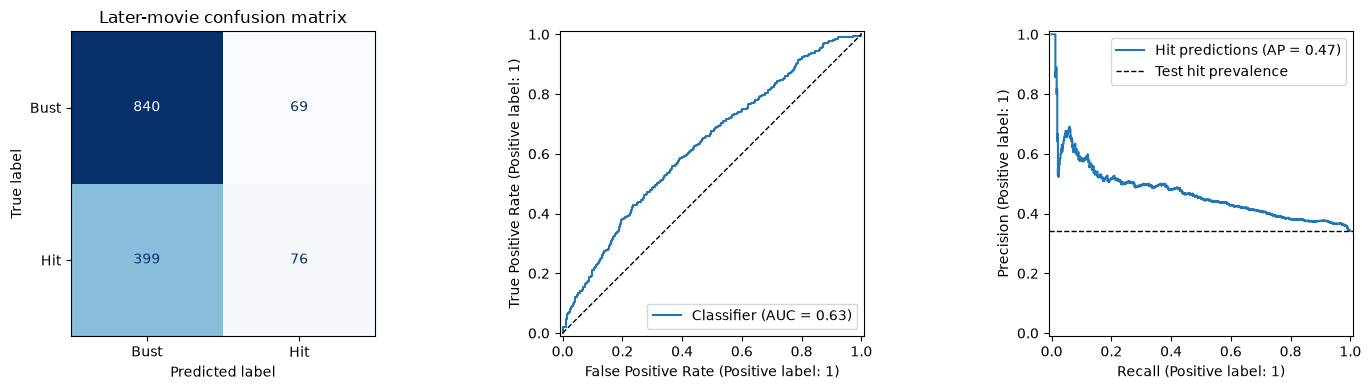

In [9]:
prediction_examples = movies.loc[test_mask, ["title_tmdb", "release_date", "success"]].copy()
prediction_examples["hit_probability"] = test_probability
prediction_examples["predicted_success"] = test_prediction
prediction_examples["correct"] = prediction_examples["success"].eq(test_prediction)
display(prediction_examples.head(10).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, labels=[0, 1], display_labels=["Bust", "Hit"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Later-movie confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[1], name="Classifier")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[2], name="Hit predictions")
axes[2].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label="Test hit prevalence")
axes[2].legend()
plt.tight_layout()
plt.show()

## 7. Inspect PCA and compare against KNN without PCA
Show how many components remain and how much training input variance they retain. Compare fixed original KNN settings with and without PCA on identical training-validation folds. For success, this diagnostic uses the original 0.5 threshold; final precision/F1 selection is reported separately.

Selected input width: 56; retained components: 42
Retained training input variance: 95.191%
Selected settings: {'pca__n_components': 0.95, 'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}


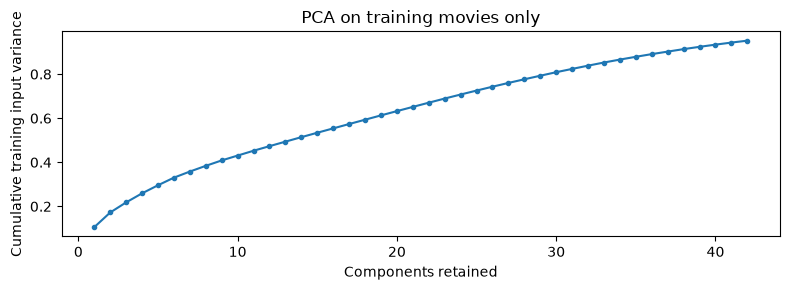

,Hit precision,Hit recall,Hit F1,ROC AUC
Version,,,,
KNN without PCA,0.6109,0.1644,0.2541,0.6416
KNN with PCA,0.6045,0.1608,0.2488,0.6326


This fixed-settings validation comparison isolates PCA; test results did not select either version.


In [10]:
from sklearn.base import clone
pca_step = model.named_steps["pca"]
encoded_width = model.named_steps["scaler"].n_features_in_
print(f"Selected input width: {encoded_width}; retained components: {pca_step.n_components_}")
print(f"Retained training input variance: {pca_step.explained_variance_ratio_.sum():.3%}")
print("Selected settings:", {key: model.get_params()[key] for key in PARAM_GRID})
assert pca_step.n_samples_ == len(y_train)
assert int(model.named_steps["scaler"].n_samples_seen_) == len(y_train)
assert set(selected_feature_columns).isdisjoint(ID_COLUMNS + TARGET_COLUMNS)
plt.figure(figsize=(8, 3))
plt.plot(np.arange(1, pca_step.n_components_ + 1), np.cumsum(pca_step.explained_variance_ratio_), marker=".")
plt.xlabel("Components retained")
plt.ylabel("Cumulative training input variance")
plt.title("PCA on training movies only")
plt.tight_layout()
plt.show()

# Original fixed KNN settings and all features: isolate PCA's effect using identical folds.
ablation_rows = []
for name in ["KNN without PCA", "KNN with PCA"]:
    for fold, (fit_positions, validation_positions) in enumerate(tuning_splits, 1):
        candidate = clone(initial_model)
        if name == "KNN without PCA":
            candidate.set_params(pca="passthrough")
        candidate.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
        actual = y_train.iloc[validation_positions]
        probability = candidate.predict_proba(X_train.iloc[validation_positions])[:, list(candidate.classes_).index(1)]
        predicted = (probability >= BASE_THRESHOLD).astype(int)
        metrics = {"Hit precision": precision_score(actual, predicted, zero_division=0), "Hit recall": recall_score(actual, predicted, zero_division=0), "Hit F1": f1_score(actual, predicted, zero_division=0), "ROC AUC": roc_auc_score(actual, probability)}
        ablation_rows.append({"Version": name, "Fold": fold, **metrics})
pca_ablation = pd.DataFrame(ablation_rows)
display(pca_ablation.groupby("Version", sort=False).mean(numeric_only=True).drop(columns="Fold").round(4))
assert len(pca_ablation) == 2 * N_VALIDATION_SPLITS
print("This fixed-settings validation comparison isolates PCA; test results did not select either version.")
# Provide the original all-feature folds to the shared visualization report.
feature_fold_results = selection_fold_results.loc[selection_fold_results["Settings"].eq("Initial settings") & selection_fold_results["Feature set"].eq("All features")].rename(columns={"Feature set": "Version"}).copy()


## Refresh the visualization report
This final cell saves metrics and prediction summaries for [the visualization notebook](../../Data_visualization/model_visualizations.ipynb). It does not write or modify dataset CSVs. Save this notebook before running all cells so report freshness checks match the code.

In [11]:
from pathlib import Path
import importlib.util

report_module_path = Path("../../Data_visualization/model_reports.py")
report_spec = importlib.util.spec_from_file_location("project_model_reports", report_module_path)
report_tools = importlib.util.module_from_spec(report_spec)
report_spec.loader.exec_module(report_tools)
report_path = report_tools.save_model_report(globals(), Path("knn_pca.ipynb"))
print("Visualization report saved:", report_path)

Visualization report saved: /Users/waltroou/DS-6021/DS_Final_Project/DS6021_Group2_FinalProject/Data_visualization/results/success/knn_pca.json
